# 03 — Benchmark de trois modèles sur l'énoncé

**Question** : à partir de l'énoncé, quel type de modèle prédit le mieux les 8 tags cibles ?

| # | Modèle | Famille | Entrée | Ce qui est appris |
|---|---|---|---|---|
| 1 | **Regex TF-IDF** | règles | description lemmatisée (+ code) | une liste de mots-clés par tag |
| 2 | **Régression logistique** | linéaire | embedding SBERT de la description (768 dim.) | 8 × 769 poids |
| 3 | **MLP** | réseau de neurones | embedding SBERT de la description (768 dim.) | ~199 000 poids (1 couche cachée) |

**Protocole commun aux trois modèles**
1. **Données** : nettoyage et découpage fixes du notebook 01 (train 3 383 / val 725 / test 726, stratifié multi-label, seed 42).
2. **Choix des hyperparamètres** : validation croisée 5 folds sur train+val, critère **Macro-AP** (indépendant du seuil).
   Seule exception : la regex ne produit pas de probabilités, sa grille est donc évaluée en Macro-F1 sur val.
3. **Entraînement final** sur train avec la configuration retenue.
4. **Seuil de décision par tag**, réglé sur val.
5. **Une seule évaluation sur test**, jamais utilisé avant.

Chaque section entraîne un modèle et se termine par sa **fiche résultat** au même format. La section 4 réunit les fiches
dans une synthèse.

In [1]:
import itertools
import logging
import sys
import time
from dataclasses import replace
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import RegexTagger, fit_keyword_tagger
from src.config import SEED, TARGET_TAGS, FeatureConfig, LogRegConfig, MLPConfig, RegexConfig, TopicConfig, TuningConfig
from src.data import load_modeling_data
from src.evaluate import (
    apply_thresholds,
    bootstrap_macro_f1_diff,
    cross_val_scores,
    global_metrics,
    grid_search,
    per_tag_metrics,
    tune_thresholds,
)
from src.features import TFIDF_DESC_BLOCK, load_encoder
from src.models import block_model, build_logreg, fit_predict_logreg, fit_predict_mlp, predict_proba, train_mlp
from src.preprocessing import normalize_text
from src.split import build_label_matrix

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

TOPIC_CFG, FEATURE_CFG = TopicConfig(), FeatureConfig()
REGEX_CFG, LOGREG_CFG, MLP_CFG = RegexConfig(), LogRegConfig(), MLPConfig()
TUNING_CFG = TuningConfig()

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 21:16:00.449000 65229 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
data = load_modeling_data(TOPIC_CFG)
df, x, y, pos = data.df, data.x, data.y, data.positions
train_df, val_df, test_df = (df.iloc[pos[s]] for s in ("train", "val", "test"))
x_dev, y_dev = data.dev()

print({s: x[s].shape for s in x})
pd.DataFrame({s: y[s].mean(axis=0) for s in ("train", "val", "test")}, index=TARGET_TAGS).style.format("{:.1%}")

{'train': (3383, 768), 'val': (725, 768), 'test': (726, 768)}


,train,val,test
math,28.5%,28.4%,28.5%
graphs,11.0%,10.9%,11.0%
strings,8.5%,8.4%,8.4%
number theory,7.0%,6.9%,7.0%
trees,6.4%,6.3%,6.3%
geometry,3.4%,3.3%,3.3%
games,2.1%,2.1%,2.1%
probabilities,1.9%,1.8%,1.9%


Fonctions communes aux trois sections : le réglage des seuils sur val et la **fiche résultat** de chaque version de modèle.

In [3]:
predictions: dict[str, np.ndarray] = {}
results: dict[str, dict] = {}


def threshold_and_predict(proba_val: np.ndarray, proba_test: np.ndarray) -> np.ndarray:
    """Seuil par tag réglé sur val, appliqué aux probabilités du test."""
    return apply_thresholds(proba_test, tune_thresholds(y["val"], proba_val))


def record(name: str, model: str, config: str, pred_test: np.ndarray, cv_scores: list[float] | None = None) -> None:
    """Enregistre les prédictions test d'une version de modèle et ses métriques."""
    predictions[name] = pred_test
    results[name] = {
        "modèle": model,
        "configuration": config,
        "cv_macro_ap": np.mean(cv_scores) if cv_scores else np.nan,
        "cv_std": np.std(cv_scores) if cv_scores else np.nan,
        **global_metrics(y["test"], pred_test),
    }


def model_card(model: str) -> pd.DataFrame:
    """Fiche résultat : toutes les versions entraînées d'un modèle."""
    table = pd.DataFrame(results).T
    return table[table["modèle"] == model].drop(columns="modèle").astype({c: float for c in table.columns[2:]}).round(3)

## 1. Modèle 1 — Regex TF-IDF (plancher sans apprentissage statistique)

**Principe** : chaque tag a une liste de mots-clés ; le tag est prédit dès qu'un mot-clé apparaît dans l'exercice.

**Entraînement**
- **Vocabulaire** : pour chaque tag, les termes au plus fort score TF-IDF par tag (notebook 02), calculés **sur le train
  uniquement** : les `k_desc` meilleurs termes de la description lemmatisée et les `k_code` meilleurs tokens du code.
- **Filtre `desc_min_lift`** : un terme n'est gardé que s'il est au moins `min_lift` fois plus marqué pour le tag que pour les
  exercices sans tag cible (élimine les termes génériques comme « positive integer »).
- **Hyperparamètres** (`k_desc`, `k_code`, `desc_min_lift`) : grille évaluée en Macro-F1 sur val.
- **Code** : pour chaque tag, on décide sur val si les mots-clés du code sont ajoutés à ceux de la description.

**Inférence** : la description est lemmatisée comme au train, puis les regex sont appliquées.

**Référence** : une regex à vocabulaire écrit à la main (`regex manuelle`), sans aucun réglage.

In [4]:
# Version de référence : vocabulaire écrit à la main
record("regex manuelle", "regex", "vocabulaire manuel", RegexTagger().predict(test_df["text_clean"]))

# Grille sur val : vocabulaire appris sur train pour chaque combinaison
train_labels = build_label_matrix(train_df["tags"])
regex_grid = []
for desc_min_lift, k_desc, k_code in itertools.product((2, 3, 5, 10), (2, 3, 5, 10), (1, 2, 3, 5, 10)):
    cfg = replace(REGEX_CFG, desc_min_lift=desc_min_lift, k_desc=k_desc, k_code=k_code)
    tagger = fit_keyword_tagger(train_df["prob_desc_description"], train_df["source_code"], train_labels, cfg)
    tagger.choose_code_usage(val_df["prob_desc_description"], val_df["source_code"], y["val"])
    val_pred = tagger.predict(val_df["prob_desc_description"], val_df["source_code"])
    regex_grid.append(
        {"desc_min_lift": desc_min_lift, "k_desc": k_desc, "k_code": k_code, "val_macro_f1": global_metrics(y["val"], val_pred)["macro_f1"]}
    )
regex_grid = pd.DataFrame(regex_grid).sort_values("val_macro_f1", ascending=False, ignore_index=True)
print(f"{len(regex_grid)} configurations testées ; les 5 meilleures (Macro-F1 val) :")
regex_grid.head(5).round(3)

80 configurations testées ; les 5 meilleures (Macro-F1 val) :


,desc_min_lift,k_desc,k_code,val_macro_f1
0,5,2,5,0.501
1,5,2,3,0.497
2,2,2,5,0.497
3,5,2,2,0.494
4,5,2,10,0.493


In [5]:
# Entraînement final avec la meilleure configuration : vocabulaire retenu par tag
best = regex_grid.iloc[0]
regex_cfg = replace(REGEX_CFG, desc_min_lift=float(best["desc_min_lift"]), k_desc=int(best["k_desc"]), k_code=int(best["k_code"]))
keyword_tagger = fit_keyword_tagger(train_df["prob_desc_description"], train_df["source_code"], train_labels, regex_cfg)
keyword_tagger.choose_code_usage(val_df["prob_desc_description"], val_df["source_code"], y["val"])

pd.DataFrame(
    {
        "mots-clés description": {t: ", ".join(w) for t, w in keyword_tagger.desc_terms.items()},
        "mots-clés code": {t: ", ".join(w) for t, w in keyword_tagger.code_terms.items()},
        "code utilisé": dict(zip(TARGET_TAGS, keyword_tagger.use_code)),
    }
)

,mots-clés description,mots-clés code,code utilisé
math,"divisible, divisor","pow, lru_cache, primes, fact, factor",True
graphs,"connected, graph","edges, node, visited, stack, popleft",True
strings,"string, letter","ord, chr, replace, 97, lower",False
number theory,"divisor, greatest","gcd, pow, prime, primes, factor",True
trees,"tree, vertex","parent, node, dfs, root, tree",False
geometry,"plane, point","x1, x2, y1, y2, points",False
games,"play optimally, optimally","Alice, Bob, odd, even, win",False
probabilities,"probability, expected","pow, random, 998244353, prob, randint",False


### Fiche résultat — Regex

In [6]:
record(
    "regex TF-IDF", "regex",
    f"k_desc={regex_cfg.k_desc}, k_code={regex_cfg.k_code}, min_lift={regex_cfg.desc_min_lift:g}",
    keyword_tagger.predict(test_df["prob_desc_description"], test_df["source_code"]),
)
model_card("regex")

,configuration,cv_macro_ap,cv_std,micro_f1,macro_f1,hamming_loss,jaccard_samples
regex manuelle,vocabulaire manuel,NaN,NaN,0.459,0.482,0.12,0.417
regex TF-IDF,"k_desc=2, k_code=5, min_lift=5",NaN,NaN,0.454,0.518,0.10,0.494


## 2. Modèle 2 — Régression logistique sur les embeddings SBERT

**Principe** : 8 régressions logistiques indépendantes (une par tag, *one-vs-rest*). Chacune calcule
$P(\text{tag} \mid x) = \sigma(w^\top x + b)$ à partir de l'embedding $x$ de la description (768 dimensions, `all-mpnet-base-v2`).

**Entraînement**
- Pénalité $L_2$ de force $1/C$ et `class_weight="balanced"` pour compenser la rareté des tags.
- **Hyperparamètres testés en CV** : `C` (régularisation) et une **PCA** optionnelle (`n_components`) pour réduire les 768
  dimensions avant la régression.

**Variante** : même modèle, mais sur une **TF-IDF de la description lemmatisée** (vecteur creux) au lieu de l'embedding.

### 2.1 Faut-il réduire les 768 dimensions ? Variance expliquée par la PCA

Si quelques composantes concentraient l'essentiel de la variance, une PCA réduirait le nombre de poids sans perte de signal.

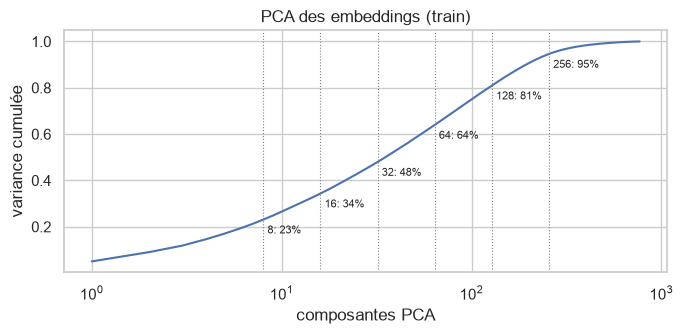

Composantes nécessaires pour 90 % de la variance : 194


In [7]:
cumulative = np.cumsum(PCA(random_state=SEED).fit(x["train"]).explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative)
for k in (8, 16, 32, 64, 128, 256):
    ax.axvline(k, color="gray", linestyle=":", linewidth=0.8)
    ax.annotate(f"{k}: {cumulative[k - 1]:.0%}", (k, cumulative[k - 1]), textcoords="offset points", xytext=(3, -10), fontsize=8)
ax.set(xscale="log", xlabel="composantes PCA", ylabel="variance cumulée", title="PCA des embeddings (train)")
plt.tight_layout()
plt.show()
print(f"Composantes nécessaires pour 90 % de la variance : {np.searchsorted(cumulative, 0.9) + 1}")

### 2.2 Choix de `n_components` et `C` en validation croisée

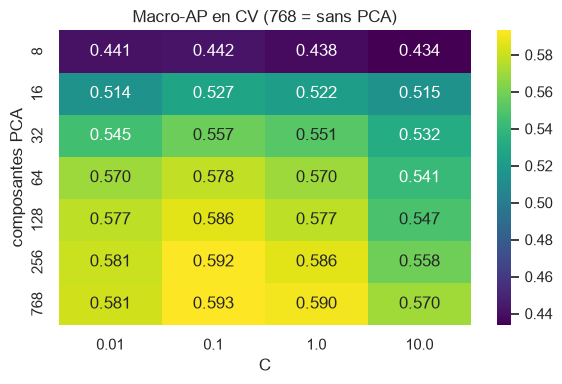

,n_components,C,cv_macro_ap,cv_std,seconds
0,NaN,0.1,0.5932,0.0329,0.1260
1,256.0,0.1,0.5924,0.0327,0.3306
2,NaN,1.0,0.5904,0.0334,0.1621
3,256.0,1.0,0.5861,0.0327,0.3606
4,128.0,0.1,0.5860,0.0323,0.2134


In [8]:
logreg_grid = grid_search(
    dict(TUNING_CFG.logreg_grid),
    lambda params: partial(fit_predict_logreg, replace(LOGREG_CFG, **params)),
    x_dev, y_dev, TUNING_CFG.n_splits,
)
heatmap = logreg_grid.assign(n_components=logreg_grid["n_components"].fillna(768).astype(int)).pivot(
    index="n_components", columns="C", values="cv_macro_ap"
)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(heatmap, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set(title="Macro-AP en CV (768 = sans PCA)", ylabel="composantes PCA")
plt.tight_layout()
plt.show()
logreg_grid.head(5).round(4)

### 2.3 Entraînement final et seuils

On entraîne la configuration par défaut (`C=1`, sans PCA), la meilleure configuration de la CV, et la variante TF-IDF.

In [9]:
def cv_logreg(cfg: LogRegConfig) -> list[float]:
    return cross_val_scores(partial(fit_predict_logreg, cfg), x_dev, y_dev, TUNING_CFG.n_splits)


def fit_logreg(cfg: LogRegConfig) -> np.ndarray:
    model = build_logreg(cfg).fit(x["train"], y["train"])
    return threshold_and_predict(model.predict_proba(x["val"]), model.predict_proba(x["test"]))


best = logreg_grid.iloc[0]
tuned_cfg = LogRegConfig(n_components=None if pd.isna(best["n_components"]) else int(best["n_components"]), C=float(best["C"]))
record("logreg (C=1)", "logreg", "SBERT, sans PCA, C=1", fit_logreg(LOGREG_CFG), cv_logreg(LOGREG_CFG))
record(f"logreg (C={tuned_cfg.C:g})", "logreg", f"SBERT, PCA={tuned_cfg.n_components}, C={tuned_cfg.C:g} (meilleure CV)",
       fit_logreg(tuned_cfg), cv_logreg(tuned_cfg))

# Variante : TF-IDF de la description lemmatisée (vocabulaire et IDF appris dans chaque fold)
descriptions = {s: d["prob_desc_description"].fillna("").to_numpy(dtype=object) for s, d in
                {"train": train_df, "val": val_df, "test": test_df}.items()}
desc_dev = np.concatenate([descriptions["train"], descriptions["val"]])


def fit_predict_tfidf(x_train, y_train, x_eval, y_eval):
    return block_model(TFIDF_DESC_BLOCK, FEATURE_CFG).fit(x_train, y_train).predict_proba(x_eval)


tfidf_model = block_model(TFIDF_DESC_BLOCK, FEATURE_CFG).fit(descriptions["train"], y["train"])
record(
    "logreg TF-IDF", "logreg", f"TF-IDF description (min_df={FEATURE_CFG.tfidf_desc_min_df}), C={FEATURE_CFG.tfidf_desc_C:g}",
    threshold_and_predict(tfidf_model.predict_proba(descriptions["val"]), tfidf_model.predict_proba(descriptions["test"])),
    cross_val_scores(fit_predict_tfidf, desc_dev, y_dev, TUNING_CFG.n_splits),
)

### Fiche résultat — Régression logistique

In [10]:
model_card("logreg")

,configuration,cv_macro_ap,cv_std,micro_f1,macro_f1,hamming_loss,jaccard_samples
logreg (C=1),"SBERT, sans PCA, C=1",0.590,0.033,0.554,0.612,0.083,0.532
logreg (C=0.1),"SBERT, PCA=None, C=0.1 (meilleure CV)",0.593,0.033,0.536,0.585,0.094,0.469
logreg TF-IDF,"TF-IDF description (min_df=10), C=1",0.581,0.023,0.555,0.588,0.084,0.546


## 3. Modèle 3 — MLP sur les embeddings SBERT

**Principe** : un réseau à une couche cachée, `768 → Linear(256) → ReLU → Dropout → Linear(8)`, avec une sortie sigmoïde par
tag (multi-label : les tags ne s'excluent pas). Il peut capter des interactions non linéaires entre dimensions de l'embedding.

**Entraînement**
- Loss `BCEWithLogitsLoss` avec `pos_weight = n_neg / n_pos` par tag, l'équivalent de `class_weight="balanced"`.
- Optimiseur AdamW, batchs de 64, **early stopping** sur la loss de validation (`patience=15`).
- **Hyperparamètres testés en CV** : `lr`, `weight_decay` (régularisation $L_2$) et `dropout`, en deux passes : la 2ᵉ prolonge
  la grille car l'optimum de la 1ʳᵉ est sur son bord (régularisation maximale).

### 3.1 Choix de `lr`, `weight_decay` et `dropout` en validation croisée

34 configurations testées en 155s


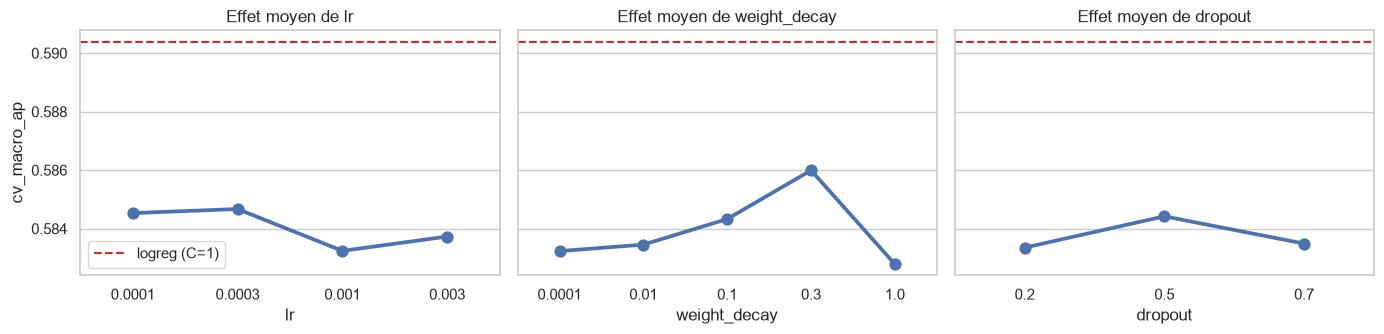

,lr,weight_decay,dropout,cv_macro_ap,cv_std,seconds,passe
0,0.0030,0.3,0.5,0.5883,0.0305,2.2663,2
1,0.0030,0.1,0.5,0.5876,0.0282,2.2485,1
2,0.0030,1.0,0.5,0.5867,0.0342,3.8513,2
3,0.0030,0.3,0.7,0.5863,0.0346,2.6215,2
4,0.0003,0.1,0.5,0.5854,0.0309,5.2241,1


In [11]:
make_mlp = lambda params: partial(fit_predict_mlp, replace(MLP_CFG, **params))  # noqa: E731
start = time.perf_counter()
mlp_grid = pd.concat(
    [
        grid_search(dict(TUNING_CFG.mlp_grid), make_mlp, x_dev, y_dev, TUNING_CFG.n_splits).assign(passe=1),
        grid_search(dict(TUNING_CFG.mlp_refine_grid), make_mlp, x_dev, y_dev, TUNING_CFG.n_splits).assign(passe=2),
    ]
).drop_duplicates(["lr", "weight_decay", "dropout"]).sort_values("cv_macro_ap", ascending=False, ignore_index=True)
print(f"{len(mlp_grid)} configurations testées en {time.perf_counter() - start:.0f}s")

logreg_cv = results["logreg (C=1)"]["cv_macro_ap"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, param in zip(axes, ["lr", "weight_decay", "dropout"]):
    sns.pointplot(data=mlp_grid, x=param, y="cv_macro_ap", ax=ax, errorbar=None, native_scale=False)
    ax.axhline(logreg_cv, color="tab:red", linestyle="--", label="logreg (C=1)")
    ax.set(title=f"Effet moyen de {param}")
axes[0].legend()
plt.tight_layout()
plt.show()
mlp_grid.head(5).round(4)

### 3.2 Entraînement final et seuils

On entraîne la configuration par défaut et la meilleure configuration de la CV. Les courbes montrent où l'early stopping
arrête l'apprentissage.

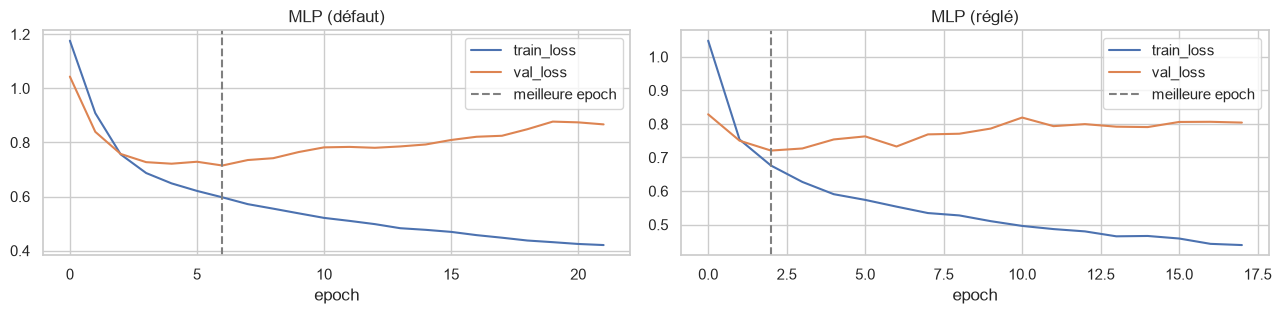

In [12]:
best = mlp_grid.iloc[0]
tuned_mlp_cfg = replace(MLP_CFG, lr=float(best["lr"]), weight_decay=float(best["weight_decay"]), dropout=float(best["dropout"]))
mlp_versions = {
    "MLP (défaut)": (MLP_CFG, "défaut"),
    "MLP (réglé)": (tuned_mlp_cfg, "meilleure CV"),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.3))
for ax, (name, (cfg, label)) in zip(axes, mlp_versions.items()):
    model, history = train_mlp(x["train"], y["train"], x["val"], y["val"], cfg)
    record(
        name, "MLP", f"lr={cfg.lr:g}, wd={cfg.weight_decay:g}, dropout={cfg.dropout:g} ({label})",
        threshold_and_predict(predict_proba(model, x["val"]), predict_proba(model, x["test"])),
        cross_val_scores(partial(fit_predict_mlp, cfg), x_dev, y_dev, TUNING_CFG.n_splits),
    )
    history.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax, title=name)
    ax.axvline(history["val_loss"].idxmin(), color="gray", linestyle="--", label="meilleure epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Stabilité vis-à-vis de l'initialisation

Contrairement à la régression logistique (problème convexe, solution unique), le MLP dépend de sa graine aléatoire.

In [13]:
seed_scores = []
for seed in range(5):
    model, _ = train_mlp(x["train"], y["train"], x["val"], y["val"], tuned_mlp_cfg, seed=seed)
    pred = threshold_and_predict(predict_proba(model, x["val"]), predict_proba(model, x["test"]))
    seed_scores.append(global_metrics(y["test"], pred)["macro_f1"])
print(f"MLP réglé, 5 graines : Macro-F1 test {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f} "
      f"(min {min(seed_scores):.3f}, max {max(seed_scores):.3f})")

MLP réglé, 5 graines : Macro-F1 test 0.562 ± 0.011 (min 0.551, max 0.582)


### Fiche résultat — MLP

In [14]:
model_card("MLP")

,configuration,cv_macro_ap,cv_std,micro_f1,macro_f1,hamming_loss,jaccard_samples
MLP (défaut),"lr=0.001, wd=0.0001, dropout=0.3 (défaut)",0.584,0.032,0.532,0.575,0.105,0.437
MLP (réglé),"lr=0.003, wd=0.3, dropout=0.5 (meilleure CV)",0.588,0.030,0.515,0.543,0.097,0.456


## 4. Synthèse des trois modèles

### 4.1 Tableau récapitulatif (test, 726 exercices)

`cv_macro_ap` sert au **choix** des modèles ; les colonnes du test servent au **constat final**. La regex n'a pas de
`cv_macro_ap` car elle ne produit pas de probabilités.

In [15]:
summary = pd.DataFrame(results).T
summary[summary.columns[2:]] = summary[summary.columns[2:]].astype(float)
(
    summary.style.format(precision=3, na_rep="—")
    .highlight_max(subset=["cv_macro_ap", "micro_f1", "macro_f1", "jaccard_samples"], color="#c6efce")
    .highlight_min(subset=["hamming_loss"], color="#c6efce")
)

,modèle,configuration,cv_macro_ap,cv_std,micro_f1,macro_f1,hamming_loss,jaccard_samples
regex manuelle,regex,vocabulaire manuel,—,—,0.459,0.482,0.120,0.417
regex TF-IDF,regex,"k_desc=2, k_code=5, min_lift=5",—,—,0.454,0.518,0.100,0.494
logreg (C=1),logreg,"SBERT, sans PCA, C=1",0.590,0.033,0.554,0.612,0.083,0.532
logreg (C=0.1),logreg,"SBERT, PCA=None, C=0.1 (meilleure CV)",0.593,0.033,0.536,0.585,0.094,0.469
logreg TF-IDF,logreg,"TF-IDF description (min_df=10), C=1",0.581,0.023,0.555,0.588,0.084,0.546
MLP (défaut),MLP,"lr=0.001, wd=0.0001, dropout=0.3 (défaut)",0.584,0.032,0.532,0.575,0.105,0.437
MLP (réglé),MLP,"lr=0.003, wd=0.3, dropout=0.5 (meilleure CV)",0.588,0.030,0.515,0.543,0.097,0.456


### 4.2 F1 par tag des trois modèles

Une version par modèle : la regex TF-IDF, la régression logistique par défaut et le MLP réglé.

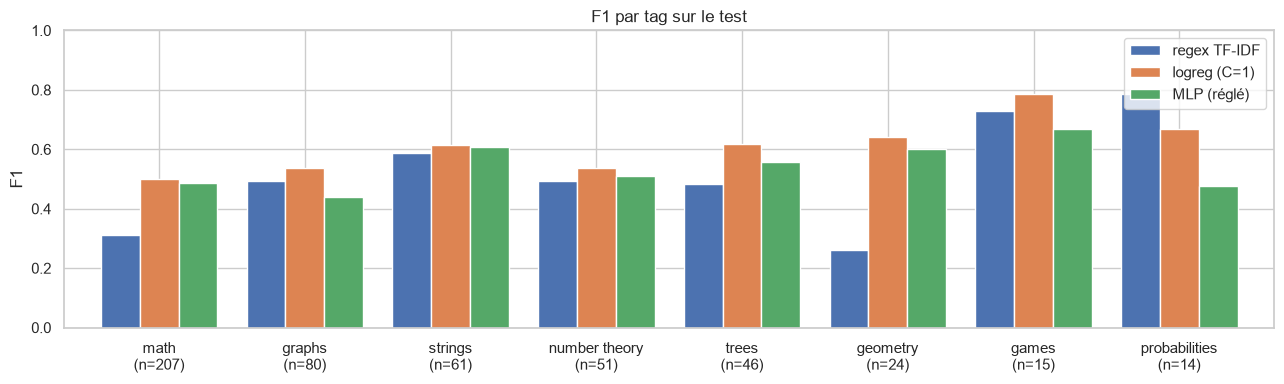

,math,graphs,strings,number theory,trees,geometry,games,probabilities
regex TF-IDF,0.31,0.49,0.59,0.49,0.48,0.26,0.73,0.79
logreg (C=1),0.50,0.54,0.61,0.54,0.62,0.64,0.79,0.67
MLP (réglé),0.49,0.44,0.61,0.51,0.56,0.60,0.67,0.48


In [16]:
champions = ["regex TF-IDF", "logreg (C=1)", "MLP (réglé)"]
f1_by_tag = pd.DataFrame({name: per_tag_metrics(y["test"], predictions[name], TARGET_TAGS)["f1"] for name in champions})
support = y["test"].sum(axis=0)

fig, ax = plt.subplots(figsize=(13, 4))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.8)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TARGET_TAGS, support)])
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
f1_by_tag.T.round(2)

### 4.3 Les écarts sont-ils significatifs ?

Bootstrap apparié (1 000 tirages des 726 exercices du test) sur la différence de Macro-F1. Un écart est significatif si son
intervalle de confiance à 95 % exclut 0.

In [17]:
pairs = [
    ("regex TF-IDF", "regex manuelle"),
    ("logreg (C=1)", "regex TF-IDF"),
    ("logreg (C=1)", "logreg TF-IDF"),
    ("logreg (C=1)", "MLP (défaut)"),
    ("logreg (C=1)", "MLP (réglé)"),
]
pd.DataFrame(
    {f"{a} − {b}": bootstrap_macro_f1_diff(y["test"], predictions[a], predictions[b], TUNING_CFG.n_bootstrap) for a, b in pairs}
).T.round(3)

,diff_mean,ci_low,ci_high,p_a_better
regex TF-IDF − regex manuelle,0.036,-0.001,0.073,0.972
logreg (C=1) − regex TF-IDF,0.093,0.044,0.144,1.000
logreg (C=1) − logreg TF-IDF,0.024,-0.019,0.069,0.853
logreg (C=1) − MLP (défaut),0.038,0.007,0.071,0.995
logreg (C=1) − MLP (réglé),0.070,0.028,0.118,0.999


### 4.4 Latence d'inférence (contrainte : < 10 s par exemple)

Temps pour prédire un exercice brut, encodage SBERT compris pour les modèles 2 et 3 (médiane sur 50 exercices, CPU/MPS local).

In [18]:
encoder = load_encoder(TOPIC_CFG.embedding_model)
logreg_model = build_logreg(LOGREG_CFG).fit(x["train"], y["train"])
mlp_model, _ = train_mlp(x["train"], y["train"], x["val"], y["val"], tuned_mlp_cfg)
encode = lambda text: encoder.encode([normalize_text(text)], normalize_embeddings=True)  # noqa: E731
encode(test_df["prob_desc_description"].iloc[0])  # warm-up

predictors = {
    "regex TF-IDF": lambda i: keyword_tagger.predict(test_df["prob_desc_description"].iloc[[i]], test_df["source_code"].iloc[[i]]),
    "logreg (C=1)": lambda i: logreg_model.predict_proba(encode(test_df["prob_desc_description"].iloc[i])),
    "MLP (réglé)": lambda i: predict_proba(mlp_model, encode(test_df["prob_desc_description"].iloc[i])),
}
latency = {}
for name, predict in predictors.items():
    times = []
    for i in range(50):
        t0 = time.perf_counter()
        predict(i)
        times.append(time.perf_counter() - t0)
    latency[name] = {"médiane (ms)": np.median(times) * 1000, "max (ms)": np.max(times) * 1000}
pd.DataFrame(latency).T.round(1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14987.19it/s]

WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


,médiane (ms),max (ms)
regex TF-IDF,0.4,1.0
logreg (C=1),15.4,33.5
MLP (réglé),14.8,30.7


### 4.5 Erreurs du modèle retenu (régression logistique, C=1)

In [19]:
best_pred = predictions["logreg (C=1)"]
errors = pd.DataFrame(
    {
        "faux positifs": ((best_pred == 1) & (y["test"] == 0)).sum(axis=0),
        "faux négatifs": ((best_pred == 0) & (y["test"] == 1)).sum(axis=0),
        "support": support,
    },
    index=TARGET_TAGS,
)
display(errors)

for kind, tag in [("faux négatifs", "math"), ("faux positifs", "number theory")]:
    k = TARGET_TAGS.index(tag)
    pred, true = best_pred[:, k], y["test"][:, k]
    mask = (pred == 0) & (true == 1) if kind == "faux négatifs" else (pred == 1) & (true == 0)
    print(f"=== {tag} : {kind} ===")
    for sid, row in test_df[mask].head(2).iterrows():
        print(f"  [{sid}] tags={row['tags']} -> {row['prob_desc_description'][:150]}...")

,faux positifs,faux négatifs,support
math,133,94,207
graphs,45,34,80
strings,25,23,61
number theory,28,22,51
trees,28,13,46
geometry,14,6,24
games,2,4,15
probabilities,8,3,14


=== math : faux négatifs ===
  [4] tags=['binary search', 'divide and conquer', 'brute force', 'math'] -> Thanos wants to destroy the avengers base, but he needs to destroy the avengers along with their base.Let we represent their base with an array, where...
  [40] tags=['number theory', 'bitmasks', 'math', 'strings'] -> You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t...
=== number theory : faux positifs ===
  [38] tags=['dp', 'combinatorics', 'brute force'] -> The Travelling Salesman spends a lot of time travelling so he tends to get bored. To pass time, he likes to perform operations on numbers. One such op...
  [97] tags=['dp', 'hashing', 'data structures', 'binary search', 'strings'] -> Vasya owns three big integers — $$$a, l, r$$$. Let's define a partition of $$$x$$$ such a sequence of strings $$$s_1, s_2, \dots, s_k$$$ that $$$s_1 +...


### 4.6 Conclusions

| Modèle | Verdict |
|---|---|
| **Regex TF-IDF** | Plancher utile : le vocabulaire appris bat le vocabulaire manuel, mais un mot-clé ne suffit pas à reconnaître une technique de résolution. |
| **Régression logistique** | **Meilleur modèle.** Nettement au-dessus de la regex, aussi bon que la variante TF-IDF, rapide et déterministe. |
| **MLP** | Pas de gain : sur ~3 400 exemples et des embeddings déjà structurés, la couche cachée ajoute surtout de la variance. |

- **La PCA n'aide pas** : l'information est répartie sur toutes les dimensions (~190 composantes pour 90 % de la variance) ; la
  régularisation $L_2$ suffit à contrôler le sur-apprentissage.
- **`C=1` contre `C=0.1`** : leurs Macro-AP en CV sont égales à l'écart-type près ; on garde la configuration par défaut.
- **Le MLP le plus régularisé se comporte comme un modèle linéaire** et dépend de sa graine (voir 3.3).
- **Décision** : la régression logistique sur embeddings devient le modèle de référence. Les gains suivants viendront de
  **nouvelles entrées** (code, spécifications, notes, difficulté) plutôt que d'un classifieur plus profond → **notebook 04**.